In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge, Lasso, ElasticNet, LinearRegression
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_log_error, mean_squared_error, r2_score
from sklearn.feature_selection import SequentialFeatureSelector
from scipy.stats import probplot

from pathlib import Path
folder = Path(r'C:\Users\tsher\OneDrive\Desktop\National University\Classes\DDS-8555\Assignment-3\playground-series-s4e4')
train = pd.read_csv(folder / ('train(1).csv' if (folder / 'train(1).csv').exists() else 'train.csv'))
test = pd.read_csv(folder / 'test.csv')
sample = pd.read_csv(folder / 'sample_submission.csv')
X = pd.get_dummies(train.drop(columns=['id','Rings']), dtype=float)
T = pd.get_dummies(test.drop(columns=['id']), dtype=float).reindex(columns=X.columns, fill_value=0)
y = train['Rings']
Xtr, Xval, ytr, yval = train_test_split(X, y, test_size=.2, random_state=42)
print(train.shape, test.shape, train.isna().sum().sum())

(90615, 10) (60411, 9) 0


In [2]:
models = {
    'Ridge': make_pipeline(StandardScaler(), Ridge(alpha=10)),
    'Lasso': make_pipeline(StandardScaler(), Lasso(alpha=.01, max_iter=10000)),
    'ElasticNet': make_pipeline(StandardScaler(), ElasticNet(alpha=.01, l1_ratio=.5, max_iter=10000))
}
scores = {}
for name, model in models.items():
    model.fit(Xtr, ytr)
    pred = np.maximum(model.predict(Xval), 0)
    scores[name] = np.sqrt(mean_squared_log_error(yval, pred))
print(pd.Series(scores).sort_values())
print(pd.Series(models['Lasso'][-1].coef_, index=X.columns).sort_values(key=abs, ascending=False))

ElasticNet    0.166484
Lasso         0.166724
Ridge         0.166762
dtype: float64
Shell weight      2.904024
Whole weight.1   -2.828183
Whole weight      0.800449
Height            0.756070
Diameter          0.534473
Sex_I            -0.329653
Whole weight.2   -0.307634
Sex_F             0.004470
Length            0.000000
Sex_M             0.000000
dtype: float64


In [3]:
# Forward subset selection among the five strongest Lasso predictors
important = pd.Series(abs(models['Lasso'][-1].coef_), index=X.columns).nlargest(5).index.tolist()
selector = SequentialFeatureSelector(LinearRegression(), n_features_to_select=3, direction='forward', cv=3, n_jobs=-1)
selector.fit(Xtr[important], ytr)
chosen = list(pd.Index(important)[selector.get_support()])
subset = LinearRegression().fit(Xtr[chosen], ytr)
pred = np.maximum(subset.predict(Xval[chosen]), 0)
scores['Subset'] = np.sqrt(mean_squared_log_error(yval, pred))
print('Selected:', chosen, 'RMSLE:', scores['Subset'])

Selected: ['Shell weight', 'Whole weight.1', 'Height'] RMSLE: 0.17007953425585767


In [4]:
pcr = GridSearchCV(make_pipeline(StandardScaler(), PCA(), LinearRegression()),
                   {'pca__n_components': list(range(1, min(X.shape[1], 12) + 1))},
                   cv=3, scoring='neg_mean_squared_error', n_jobs=-1)
pcr.fit(Xtr, ytr)
pred = np.maximum(pcr.predict(Xval), 0)
scores['PCR'] = np.sqrt(mean_squared_log_error(yval, pred))
print('PCR components:', pcr.best_params_)
print(pd.Series(scores).sort_values())

PCR components: {'pca__n_components': 9}
ElasticNet    0.166484
Lasso         0.166724
Ridge         0.166762
PCR           0.166774
Subset        0.170080
dtype: float64


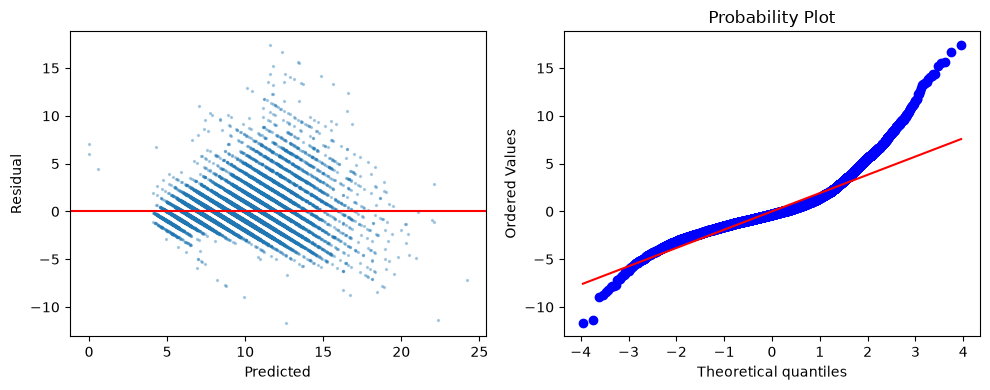

Best: ElasticNet R2: 0.5988676851330901 RMSE: 2.029919684552314
      id      Rings
0  90615   8.915553
1  90616  10.165535
2  90617  10.336647
3  90618  10.766806
4  90619   7.750298


In [5]:
best = min(scores, key=scores.get)
model = pcr.best_estimator_ if best == 'PCR' else subset if best == 'Subset' else models[best]
pred = model.predict(Xval[chosen] if best == 'Subset' else Xval)
residuals = yval - pred
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(pred, residuals, s=2, alpha=.3)
ax[0].axhline(0, color='red'); ax[0].set(xlabel='Predicted', ylabel='Residual')
probplot(residuals, dist='norm', plot=ax[1]); plt.tight_layout(); plt.show()
print('Best:', best, 'R2:', r2_score(yval, pred), 'RMSE:', np.sqrt(mean_squared_error(yval, pred)))
model.fit(X[chosen] if best == 'Subset' else X, y)
submission = sample.copy()
submission['Rings'] = np.maximum(model.predict(T[chosen] if best == 'Subset' else T), 0)
submission.to_csv(folder / 'abalone_submission.csv', index=False)
print(submission.head())

In [6]:
# Second Kaggle submission: Principal Components Regression (PCR)
pcr_final = make_pipeline(StandardScaler(), PCA(n_components=pcr.best_params_['pca__n_components']), LinearRegression())
pcr_final.fit(X, y)
pcr_submission = sample.copy()
pcr_submission['Rings'] = np.maximum(pcr_final.predict(T), 0)
pcr_submission.to_csv(folder / 'abalone_pcr_submission.csv', index=False)
print('PCR submission saved:', folder / 'abalone_pcr_submission.csv')
print(pcr_submission.head())


PCR submission saved: C:\Users\tsher\OneDrive\Desktop\National University\Classes\DDS-8555\Assignment-3\playground-series-s4e4\abalone_pcr_submission.csv
      id      Rings
0  90615   8.535442
1  90616  10.029784
2  90617  10.305835
3  90618  10.956449
4  90619   7.782893
